# Segmentasi pelanggan
 ## Tujuan demo
 Jalankan sel dari atas ke bawah. Penjelasan, tabel, dan grafik memakai keluaran run baru di `.cache/demo-notebook/clustering/`.
 Kode eksperimen utama berada di `clustering.py` dan dipanggil langsung oleh notebook ini.

 Sebelum demo, gunakan Python 3.12 dan pasang dependensi dari root repo dengan
 `python -m pip install -r kode/requirements-notebook.txt`.
 Simpan data rilis dosen di `data_uts_ml/`. Notebook ini dapat dibuka melalui JupyterLab atau VS Code.
 Untuk Colab, unggah salinan repo lengkap dan data terlebih dahulu, lalu buka notebook ini dari folder repo.

## 1. Persiapan lingkungan

In [1]:
TASK = 'clustering'
INPUTS = ['clustering.csv.gz']
from pathlib import Path
import importlib.util
import json
import os
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

current = Path.cwd().resolve()
ROOT = current if (current / "kode").is_dir() else current.parent
assert (ROOT / "kode" / (TASK + ".py")).is_file(), "Buka notebook dari root repo atau folder kode/."
DATA = Path(os.environ.get("UTS_DATA_DIR", ROOT / "data_uts_ml"))
OUTPUT = ROOT / ".cache" / "demo-notebook" / TASK
OUTPUT.mkdir(parents=True, exist_ok=True)

spec = importlib.util.spec_from_file_location("eksperimen_" + TASK, ROOT / "kode" / (TASK + ".py"))
experiment = importlib.util.module_from_spec(spec)
spec.loader.exec_module(experiment)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.axisbelow": True})

## 2. Data dan pertanyaan
Satu baris data merepresentasikan satu pelanggan. Tampilkan lima contoh untuk membaca kolom yang dipakai.

In [2]:
sample = pd.read_csv(DATA / INPUTS[0], nrows=5)
display(sample[['id_pelanggan', 'recency_hari', 'frekuensi_90h', 'persen_voucher']])

,id_pelanggan,recency_hari,frekuensi_90h,persen_voucher
0,C864291,8.8,6,0.468
1,C115620,14.6,6,0.029
2,C903774,4.1,15,0.266
3,C716498,21.9,2,0.681
4,C936513,7.0,8,0.686


## 3. Metode dan asumsi
 Kami memakai perilaku belanja, promosi, dan aktivitas setelah imputasi, transformasi, dan scaling.
 KMeans, GMM diagonal, dan Ward dibandingkan pada 2.600 pelanggan yang sama untuk k=2-8.
 Silhouette menilai pemisahan, sedangkan ARI antarsubsampel menilai kestabilan.
 Pelanggan mendapat -1 jika dua aturan anomali setuju. Label referensi dosen disembunyikan.

## 4. Jalankan ulang eksperimen
Sel ini mengulang audit, perbandingan metode, stabilitas, sensitivitas fitur, dan label pelanggan.

In [3]:
missing = [name for name in INPUTS if not (DATA / name).is_file()]
assert not missing, "Masukkan data dosen ke data_uts_ml/. Berkas belum ada: " + ", ".join(missing)
start = time.perf_counter()
subprocess.run(
    [sys.executable, str(ROOT / "kode" / (TASK + ".py")), "--data", str(DATA), "--output", str(OUTPUT)],
    check=True,
)
print(f"Eksperimen selesai dalam {time.perf_counter() - start:.1f} detik.")
metrics = json.loads((OUTPUT / "hasil" / TASK / "metrics.json").read_text(encoding="utf-8"))

Eksperimen selesai dalam 18.0 detik.


## 5. Mengapa KMeans tiga cluster?

,method,k,silhouette,ari_mean,selection_score
1,KMeans,3,0.1688,0.9738,0.1622


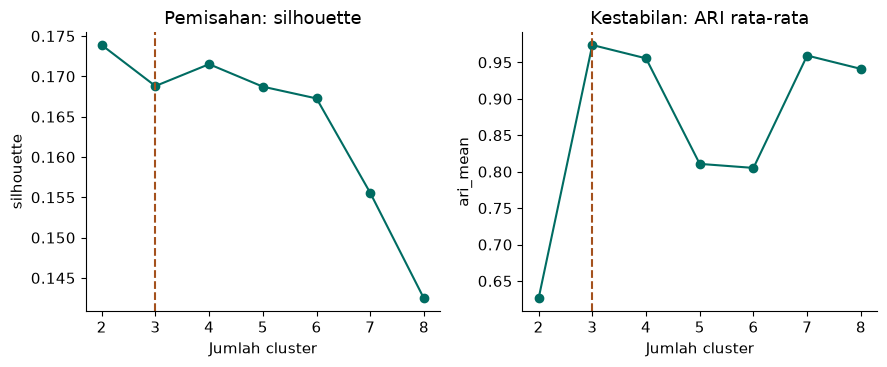

In [4]:
comparison = pd.read_csv(OUTPUT / "hasil" / TASK / "perbandingan_model.csv")
chosen = comparison.loc[(comparison["method"] == metrics["method"]) & (comparison["k"] == metrics["k"])]
display(chosen[["method", "k", "silhouette", "ari_mean", "selection_score"]].round(4))
kmeans = comparison.loc[comparison["method"] == "KMeans"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, column, title in zip(axes, ["silhouette", "ari_mean"], ["Pemisahan: silhouette", "Kestabilan: ARI rata-rata"]):
    ax.plot(kmeans["k"], kmeans[column], marker="o", color="#006C62")
    ax.axvline(metrics["k"], linestyle="--", color="#A4511D")
    ax.set(xlabel="Jumlah cluster", ylabel=column, title=title, xticks=list(range(2, 9)))
plt.tight_layout()
plt.show()

Silhouette k=3 sekitar 0,169 menunjukkan tumpang tindih. ARI 0,974 menunjukkan hasil relatif stabil saat sampel fit berubah. Kedua metrik mengukur hal berbeda.

## 6. Seperti apa pelanggan di tiap kelompok?

,cluster,n,median_recency_days,median_order_count,median_voucher
0,-1,481,12.9,9.0,0.357
1,0,39679,6.5,13.0,0.282
2,1,53357,8.6,7.0,0.722
3,2,26483,48.9,2.0,0.438


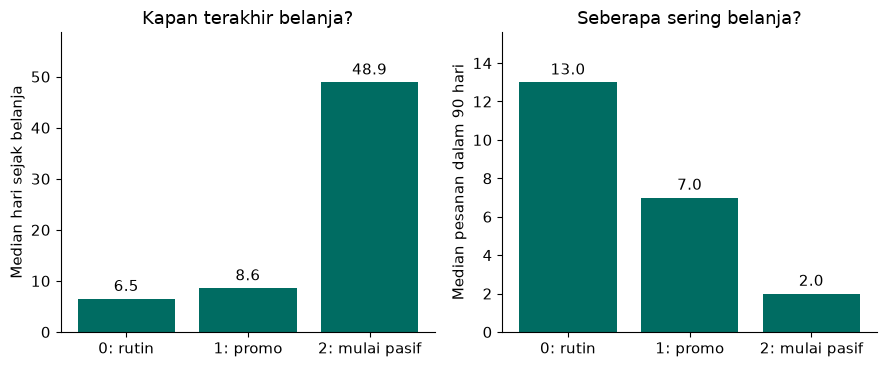

In [5]:
profiles = pd.read_csv(OUTPUT / "hasil" / TASK / "profil_segmen.csv")
display(profiles[["cluster", "n", "median_recency_days", "median_order_count", "median_voucher"]])
regular = profiles.loc[profiles["cluster"] >= 0].sort_values("cluster")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, feature, title, ylabel in [
    (axes[0], "median_recency_days", "Kapan terakhir belanja?", "Median hari sejak belanja"),
    (axes[1], "median_order_count", "Seberapa sering belanja?", "Median pesanan dalam 90 hari"),
]:
    bars = ax.bar(["0: rutin", "1: promo", "2: mulai pasif"], regular[feature], color="#006C62")
    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.margins(y=0.2)
    ax.set(title=title, ylabel=ylabel)
plt.tight_layout()
plt.show()

Kelompok 2 cenderung sudah lama tidak belanja dan jarang memesan. Kita dapat mengusulkan uji tawaran reaktivasi dengan pembanding tanpa tawaran.

## 7. Dari mana 481 anomali berasal?

In [6]:
predictions = pd.read_csv(OUTPUT / "cluster.csv")
assert predictions["id_pelanggan"].is_unique
counts = predictions["cluster"].value_counts().sort_index().rename("Pelanggan")
display(counts.to_frame())
print(f"Total {len(predictions):,}; anomali {(predictions['cluster'] == -1).sum():,}.")
display(pd.DataFrame(metrics["final"]["anomaly_sensitivity"]))

,Pelanggan
cluster,
-1,481
0,39679
1,53357
2,26483


Total 120,000; anomali 481.


,distance_percentile_per_cluster,global_isolation_percentile,n,fraction
0,0.975,0.975,677,0.005642
1,0.985,0.975,481,0.004008
2,0.990,0.975,364,0.003033


## Latihan menjawab
 Sebutkan tujuan eksperimen, satu keputusan metode, angka yang baru dihitung, dan batas kesimpulannya.
 Buka `../laporan.pdf` untuk pembahasan semua subsoal dan `../hasil/` untuk bukti tersimpan.